# MediVision AI — Chest X-ray Vision Pipeline (End-to-End)

**Purpose:** train, evaluate, explain, and export the five-label DenseNet-121 chest X-ray model used by MediVision AI.

**Target labels (fixed order / backend contract):**
1. `Cardiomegaly`
2. `Pneumonia`
3. `Effusion`
4. `Infiltration`
5. `Atelectasis`

**Deployment artifact name is intentionally preserved:** `chest_xray_densenet121.pth`

> **Important:** This is a research/development pipeline, not a clinically validated diagnostic device. NIH ChestX-ray14 labels are report-derived and noisy. Model scores are not diagnoses. Do not use for clinical decisions without independent external validation, appropriate governance, and clinician oversight.

## Kaggle setup
1. Create a Kaggle Notebook and enable a GPU accelerator (T4/P100 if available).
2. Add the **full NIH ChestX-ray14 dataset** from Kaggle as an input dataset. It should include `Data_Entry_2017.csv` and the image files (`images_*.tar.gz` must be extracted before training, or add an already-extracted dataset).
3. If pretrained ImageNet weights are not cached, enable Internet in Kaggle so torchvision can download them.
4. Run cells from top to bottom. The notebook **fails loudly** if metadata/images are missing; it never fabricates training data or substitutes fake images.
5. At the end, download `/kaggle/working/chest_xray_densenet121.pth` and put it in the same project location currently used by the backend.

This notebook keeps the original model architecture and `.pth` filename to maximize compatibility with the existing backend. It also exports a metadata JSON containing preprocessing, class order, thresholds, and training details; keep that file alongside the weights where possible.

## 1. Environment, configuration, reproducibility

Review the configuration before running. `DATASET_ROOT` can be left as `None` for automatic Kaggle input discovery. Do not set `ALLOW_MISSING_IMAGES=True` unless you intentionally want to train on an incomplete dataset.

In [2]:
import os, gc, json, time, random, warnings, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)

# ---------------- User configuration ----------------
DATASET_ROOT = "/kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized"  # e.g. Path("/kaggle/input/nih-chest-xray")
CSV_FILENAME = "Data_Entry_2017.csv"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()

TARGET_CONDITIONS = [
    "Cardiomegaly", "Pneumonia", "Effusion", "Infiltration", "Atelectasis"
]
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
NUM_WORKERS = 2
SEED = 42
USE_PRETRAINED = True
ALLOW_MISSING_IMAGES = False  # default must stay False for a full-dataset run
MAX_IMAGES = None             # None = full dataset; set an integer only for debugging
PIN_MEMORY = torch.cuda.is_available()

WEIGHTS_FILENAME = "chest_xray_densenet121.pth"  # DO NOT RENAME: backend compatibility
METADATA_FILENAME = "chest_xray_densenet121_metadata.json"
METRICS_FILENAME = "chest_xray_densenet121_metrics.json"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ImageFile.LOAD_TRUNCATED_IMAGES = False

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Reproducibility without forcing the slowest deterministic algorithms.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GiB")
else:
    warnings.warn("No GPU detected. Full NIH training on CPU may take a very long time.")
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.13.15
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: Tesla T4
GPU memory: 14.6 GiB
Output directory: /kaggle/working


## 2. Discover the full dataset and index image paths

The code searches for the NIH metadata CSV and indexes image files once (instead of recursively searching the disk for every sample). It supports nested `images_001/images/...`-style directories. It intentionally does not generate dummy rows or dummy images.

In [3]:
def discover_csv_and_root(explicit_root=None, csv_filename=CSV_FILENAME):
    if explicit_root is not None:
        root = Path(explicit_root)
        candidate = root / csv_filename
        if candidate.exists():
            return root, candidate
        matches = list(root.rglob(csv_filename)) if root.exists() else []
        if matches:
            return matches[0].parent, matches[0]
        raise FileNotFoundError(f"Could not find {csv_filename} under DATASET_ROOT={root}")

    search_roots = []
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        search_roots.append(kaggle_input)
    search_roots.append(Path.cwd())

    for search_root in search_roots:
        matches = list(search_root.rglob(csv_filename))
        if matches:
            csv_path = matches[0]
            return csv_path.parent, csv_path
    raise FileNotFoundError(
        f"Could not find {csv_filename}. Add the full NIH ChestX-ray14 Kaggle dataset "
        "to Notebook Inputs, or set DATASET_ROOT explicitly. No synthetic fallback is used."
    )

dataset_root, csv_path = discover_csv_and_root(DATASET_ROOT)
print("Dataset root:", dataset_root)
print("Metadata CSV:", csv_path)

df_raw = pd.read_csv(csv_path)
required_columns = {"Image Index", "Finding Labels", "Patient ID"}
missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Metadata is missing required columns: {sorted(missing_columns)}")

df_raw["Image Index"] = df_raw["Image Index"].astype(str).str.strip()
df_raw["Patient ID"] = df_raw["Patient ID"].astype(str).str.strip()
df_raw["Finding Labels"] = df_raw["Finding Labels"].fillna("").astype(str)

# Index common image formats. Basename lookup also supports nested image folders.
valid_exts = {".png", ".jpg", ".jpeg", ".bmp"}
print("Indexing image files (this can take a few minutes for the full dataset)...")
image_paths = {}
duplicate_names = Counter()
for p in dataset_root.rglob("*"):
    if p.is_file() and p.suffix.lower() in valid_exts:
        name = p.name
        if name in image_paths:
            duplicate_names[name] += 1
            # Keep the first deterministic path; duplicate basename ambiguity is reported below.
        else:
            image_paths[name] = p

if not image_paths:
    raise FileNotFoundError(
        f"No extracted image files found under {dataset_root}. "
        "If the Kaggle dataset contains .tar.gz archives, extract them first."
    )

# If filenames have an alternate extension, allow stem matching only when unambiguous.
stem_to_paths = {}
for name, p in image_paths.items():
    stem_to_paths.setdefault(Path(name).stem, []).append(p)

def resolve_image_name(name):
    if name in image_paths:
        return str(image_paths[name])
    candidates = stem_to_paths.get(Path(name).stem, [])
    if len(candidates) == 1:
        return str(candidates[0])
    return None

df_raw["image_path"] = df_raw["Image Index"].map(resolve_image_name)
missing_count = int(df_raw["image_path"].isna().sum())
print(f"Metadata rows: {len(df_raw):,}")
print(f"Unique patients: {df_raw['Patient ID'].nunique():,}")
print(f"Indexed image files: {len(image_paths):,}")
print(f"Rows with missing/ambiguous images: {missing_count:,}")
if duplicate_names:
    print(f"Warning: {len(duplicate_names):,} duplicate image basenames found in image tree.")

if missing_count:
    examples = df_raw.loc[df_raw["image_path"].isna(), "Image Index"].head(20).tolist()
    if not ALLOW_MISSING_IMAGES:
        raise FileNotFoundError(
            f"{missing_count:,} metadata rows do not resolve to a unique image. "
            f"Examples: {examples}. Add/extract the complete dataset or correct DATASET_ROOT. "
            "For an intentionally partial dataset only, set ALLOW_MISSING_IMAGES=True explicitly."
        )
    print("WARNING: explicitly allowing incomplete data; missing-image rows will be excluded.")
    df_raw = df_raw.loc[df_raw["image_path"].notna()].copy()

if MAX_IMAGES is not None:
    df_raw = df_raw.head(int(MAX_IMAGES)).copy()
    print(f"DEBUG MODE: restricted to {len(df_raw):,} rows. Do not use this run as a production model.")

# Parse pipe-separated labels. A row can have more than one positive finding.
label_sets = df_raw["Finding Labels"].map(lambda s: set(x.strip() for x in s.split("|") if x.strip()))
for label in TARGET_CONDITIONS:
    df_raw[label] = label_sets.map(lambda labels: int(label in labels)).astype(np.float32)
df_raw["No Finding"] = label_sets.map(lambda labels: int("No Finding" in labels)).astype(np.float32)

# Validate the labels and data.
if df_raw[TARGET_CONDITIONS].isna().any().any():
    raise ValueError("NaN labels detected.")
if not set(np.unique(df_raw[TARGET_CONDITIONS].to_numpy())).issubset({0.0, 1.0}):
    raise ValueError("Labels must be binary 0/1.")

print("\nPositive labels in full metadata:")
display(pd.DataFrame({
    "condition": TARGET_CONDITIONS,
    "positive_images": [int(df_raw[c].sum()) for c in TARGET_CONDITIONS],
    "prevalence_pct": [round(float(df_raw[c].mean()*100), 3) for c in TARGET_CONDITIONS]
}))

Dataset root: /kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
Metadata CSV: /kaggle/input/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/Data_Entry_2017.csv
Indexing image files (this can take a few minutes for the full dataset)...
Metadata rows: 112,120
Unique patients: 30,805
Indexed image files: 112,120
Rows with missing/ambiguous images: 0

Positive labels in full metadata:


,condition,positive_images,prevalence_pct
0,Cardiomegaly,2772,2.472
1,Pneumonia,1353,1.207
2,Effusion,13307,11.869
3,Infiltration,19870,17.722
4,Atelectasis,11535,10.288


## 3. Patient-level Train / Validation / Test split

Patients, not images, are the grouping unit. The split is approximately 70/15/15 by patient groups. The notebook asserts that no patient appears in more than one split and reports per-split label prevalence so imbalance is visible.

In [4]:
# GroupShuffleSplit does not guarantee multilabel stratification; prevalence is reported for audit.
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df_raw, groups=df_raw["Patient ID"]))
df_train = df_raw.iloc[train_idx].copy().reset_index(drop=True)
df_temp = df_raw.iloc[temp_idx].copy().reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED + 1)
val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp["Patient ID"]))
df_val = df_temp.iloc[val_idx].copy().reset_index(drop=True)
df_test = df_temp.iloc[test_idx].copy().reset_index(drop=True)

patient_sets = {
    "train": set(df_train["Patient ID"]),
    "validation": set(df_val["Patient ID"]),
    "test": set(df_test["Patient ID"]),
}
assert patient_sets["train"].isdisjoint(patient_sets["validation"]), "Patient leakage: train/validation"
assert patient_sets["train"].isdisjoint(patient_sets["test"]), "Patient leakage: train/test"
assert patient_sets["validation"].isdisjoint(patient_sets["test"]), "Patient leakage: validation/test"

split_rows = []
for split_name, split_df in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    row = {
        "split": split_name,
        "images": len(split_df),
        "patients": split_df["Patient ID"].nunique(),
    }
    for c in TARGET_CONDITIONS:
        row[f"{c} prevalence %"] = round(float(split_df[c].mean() * 100), 3)
    split_rows.append(row)
split_summary = pd.DataFrame(split_rows)
display(split_summary)
print("Patient-level leakage check passed.")

,split,images,patients,Cardiomegaly prevalence %,Pneumonia prevalence %,Effusion prevalence %,Infiltration prevalence %,Atelectasis prevalence %
0,train,79006,21563,2.438,1.196,12.051,17.792,10.311
1,validation,16460,4621,2.369,1.203,11.476,17.327,10.255
2,test,16654,4621,2.738,1.261,11.391,17.780,10.214


Patient-level leakage check passed.


## 4. Dataset, preprocessing, and DataLoaders

The preprocessing uses a resize that preserves aspect ratio followed by a center crop, rather than distorting every radiograph into a square. Training augmentation is deliberately conservative: small rotation and mild brightness/contrast only; no horizontal/vertical flips. Any corrupt/unreadable image raises an explicit error rather than silently substituting a fake image.

In [5]:
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD),
])

class ChestXrayDataset(Dataset):
    def __init__(self, frame, target_cols, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.target_cols = list(target_cols)
        self.transform = transform
        self.paths = self.frame["image_path"].astype(str).tolist()
        self.labels = self.frame[self.target_cols].to_numpy(dtype=np.float32)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        path = self.paths[idx]
        try:
            with Image.open(path) as im:
                image = im.convert("RGB")
                # Force decode while file is open; corrupt files fail explicitly.
                image.load()
        except Exception as exc:
            raise RuntimeError(f"Failed to read image at index {idx}: {path}") from exc
        if self.transform is not None:
            image = self.transform(image)
        target = torch.from_numpy(self.labels[idx])
        return image, target

train_ds = ChestXrayDataset(df_train, TARGET_CONDITIONS, train_transform)
val_ds = ChestXrayDataset(df_val, TARGET_CONDITIONS, eval_transform)
test_ds = ChestXrayDataset(df_test, TARGET_CONDITIONS, eval_transform)

# Avoid worker failures on constrained Kaggle sessions.
num_workers = min(NUM_WORKERS, os.cpu_count() or 1)
loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": num_workers,
    "pin_memory": PIN_MEMORY,
    "persistent_workers": num_workers > 0,
}
train_loader = DataLoader(train_ds, shuffle=True, drop_last=False, **loader_kwargs)
val_loader = DataLoader(val_ds, shuffle=False, drop_last=False, **loader_kwargs)
test_loader = DataLoader(test_ds, shuffle=False, drop_last=False, **loader_kwargs)

print(f"Train: {len(train_ds):,} images / {len(train_loader):,} batches")
print(f"Validation: {len(val_ds):,} images / {len(val_loader):,} batches")
print(f"Test: {len(test_ds):,} images / {len(test_loader):,} batches")

# Preview one real batch as a sanity check.
xb, yb = next(iter(train_loader))
assert xb.ndim == 4 and xb.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert yb.shape[1] == len(TARGET_CONDITIONS)
print("Batch tensor:", tuple(xb.shape), "labels:", tuple(yb.shape))

Train: 79,006 images / 2,469 batches
Validation: 16,460 images / 515 batches
Test: 16,654 images / 521 batches
Batch tensor: (32, 3, 224, 224) labels: (32, 5)


## 5. DenseNet-121 architecture (backend-compatible)

The classifier head deliberately matches the previous notebook's key structure: `Linear(1024, 512) → ReLU → Dropout(0.2) → Linear(512, 5)`. This preserves the state-dict key names expected by a backend built around that architecture.

In [6]:
def build_densenet121_classifier(num_classes=5, pretrained=True):
    if pretrained:
        try:
            weights = models.DenseNet121_Weights.DEFAULT
            backbone = models.densenet121(weights=weights)
        except Exception as exc:
            raise RuntimeError(
                "Could not load pretrained DenseNet-121 ImageNet weights. "
                "Enable Internet in Kaggle or ensure the weights are cached. "
                "The notebook will not silently continue with random initialization."
            ) from exc
    else:
        backbone = models.densenet121(weights=None)

    in_features = backbone.classifier.in_features
    backbone.classifier = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.2),
        nn.Linear(512, num_classes),
    )
    return backbone

model = build_densenet121_classifier(len(TARGET_CONDITIONS), pretrained=USE_PRETRAINED).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"DenseNet-121 ready: {n_params:,} parameters")
print("Output logits shape should be [batch, 5].")
with torch.no_grad():
    test_logits = model(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
assert tuple(test_logits.shape) == (2, len(TARGET_CONDITIONS))
del test_logits

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 159MB/s] 


DenseNet-121 ready: 7,481,221 parameters
Output logits shape should be [batch, 5].


## 6. Loss, optimizer, AMP, and training utilities

`BCEWithLogitsLoss` is appropriate for multi-label targets. Positive weights are calculated from the training split only and capped to reduce extreme gradients. Validation AUC is used for checkpoint selection; the test set is not used to select epochs or thresholds.

In [7]:
y_train = df_train[TARGET_CONDITIONS].to_numpy(dtype=np.float32)
positive_counts = y_train.sum(axis=0)
negative_counts = len(y_train) - positive_counts
if np.any(positive_counts == 0):
    absent = [TARGET_CONDITIONS[i] for i, n in enumerate(positive_counts) if n == 0]
    raise ValueError(f"Training split has zero positive examples for labels: {absent}")

pos_weights = np.clip(negative_counts / np.maximum(positive_counts, 1), 1.0, 50.0)
pos_weight_tensor = torch.tensor(pos_weights, dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

print("Positive weights:")
display(pd.DataFrame({"condition": TARGET_CONDITIONS, "positive_count": positive_counts.astype(int),
                      "negative_count": negative_counts.astype(int), "pos_weight": pos_weights.round(3)}))

def safe_auc_per_class(y_true, y_score):
    values = []
    for i in range(y_true.shape[1]):
        if len(np.unique(y_true[:, i])) < 2:
            values.append(np.nan)  # undefined, never substitute 0.5
        else:
            values.append(float(roc_auc_score(y_true[:, i], y_score[:, i])))
    return values

def macro_valid(values):
    valid = [v for v in values if np.isfinite(v)]
    return float(np.mean(valid)) if valid else float("nan")

def run_eval(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    n = 0
    all_y, all_p = [], []
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            with torch.amp.autocast(device_type=device.type, enabled=amp_enabled):
                logits = model(images)
                loss = criterion(logits, targets)
            probs = torch.sigmoid(logits)
            loss_sum += float(loss.item()) * images.size(0)
            n += images.size(0)
            all_y.append(targets.cpu().numpy())
            all_p.append(probs.float().cpu().numpy())
    y_true = np.concatenate(all_y, axis=0)
    y_prob = np.concatenate(all_p, axis=0)
    aucs = safe_auc_per_class(y_true, y_prob)
    return loss_sum / max(n, 1), macro_valid(aucs), aucs, y_true, y_prob

def train_one_epoch(model, loader):
    model.train()
    loss_sum, n = 0.0, 0
    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=amp_enabled):
            logits = model(images)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += float(loss.item()) * images.size(0)
        n += images.size(0)
    return loss_sum / max(n, 1)

best_weights_path = OUTPUT_DIR / "best_densenet121_checkpoint.pth"
history = {"train_loss": [], "val_loss": [], "val_macro_roc_auc": []}
best_val_auc = -float("inf")
epochs_without_improvement = 0

Positive weights:


,condition,positive_count,negative_count,pos_weight
0,Cardiomegaly,1926,77080,40.021
1,Pneumonia,945,78061,50.000
2,Effusion,9521,69485,7.298
3,Infiltration,14057,64949,4.620
4,Atelectasis,8146,70860,8.699


## 7. Train with best-checkpoint selection and early stopping

This cell can take a long time on the full dataset. Keep the Kaggle session alive until export completes. The checkpoint is saved after every improvement so a session interruption does not lose all progress.

In [8]:
start_time = time.time()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_loss = train_one_epoch(model, train_loader)
    val_loss, val_macro_auc, val_aucs, _, _ = run_eval(model, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))
    history["val_macro_roc_auc"].append(float(val_macro_auc) if np.isfinite(val_macro_auc) else None)

    improved = np.isfinite(val_macro_auc) and val_macro_auc > best_val_auc
    if improved:
        best_val_auc = val_macro_auc
        epochs_without_improvement = 0
        torch.save(model.state_dict(), best_weights_path)
        status = "BEST checkpoint saved"
    else:
        epochs_without_improvement += 1
        status = f"no improvement ({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})"

    auc_text = ", ".join(
        f"{name}={auc:.3f}" if np.isfinite(auc) else f"{name}=undefined"
        for name, auc in zip(TARGET_CONDITIONS, val_aucs)
    )
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | val_macro_AUC={val_macro_auc:.4f} | "
        f"{time.time()-epoch_start:.1f}s | {status}"
    )
    print("  Per-class validation AUC:", auc_text)

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

if not best_weights_path.exists():
    raise RuntimeError("No valid checkpoint was saved. Check the validation split and training logs.")

print(f"Training time: {(time.time()-start_time)/60:.1f} minutes")
print(f"Best validation macro ROC-AUC: {best_val_auc:.4f}")

Epoch 01/8 | train_loss=0.9823 | val_loss=0.9294 | val_macro_AUC=0.7903 | 4835.1s | BEST checkpoint saved
  Per-class validation AUC: Cardiomegaly=0.897, Pneumonia=0.732, Effusion=0.874, Infiltration=0.677, Atelectasis=0.771
Epoch 02/8 | train_loss=0.9191 | val_loss=0.9016 | val_macro_AUC=0.7930 | 439.5s | BEST checkpoint saved
  Per-class validation AUC: Cardiomegaly=0.912, Pneumonia=0.716, Effusion=0.884, Infiltration=0.673, Atelectasis=0.779
Epoch 03/8 | train_loss=0.8825 | val_loss=0.9067 | val_macro_AUC=0.7932 | 439.5s | BEST checkpoint saved
  Per-class validation AUC: Cardiomegaly=0.910, Pneumonia=0.703, Effusion=0.886, Infiltration=0.683, Atelectasis=0.783
Epoch 04/8 | train_loss=0.8440 | val_loss=0.9054 | val_macro_AUC=0.8018 | 440.7s | BEST checkpoint saved
  Per-class validation AUC: Cardiomegaly=0.912, Pneumonia=0.725, Effusion=0.888, Infiltration=0.691, Atelectasis=0.794
Epoch 05/8 | train_loss=0.7823 | val_loss=0.9203 | val_macro_AUC=0.8061 | 442.7s | BEST checkpoint save

## 8. Learning curves

Use these plots to check for obvious divergence or overfitting. A smooth loss curve is not proof of clinical validity.

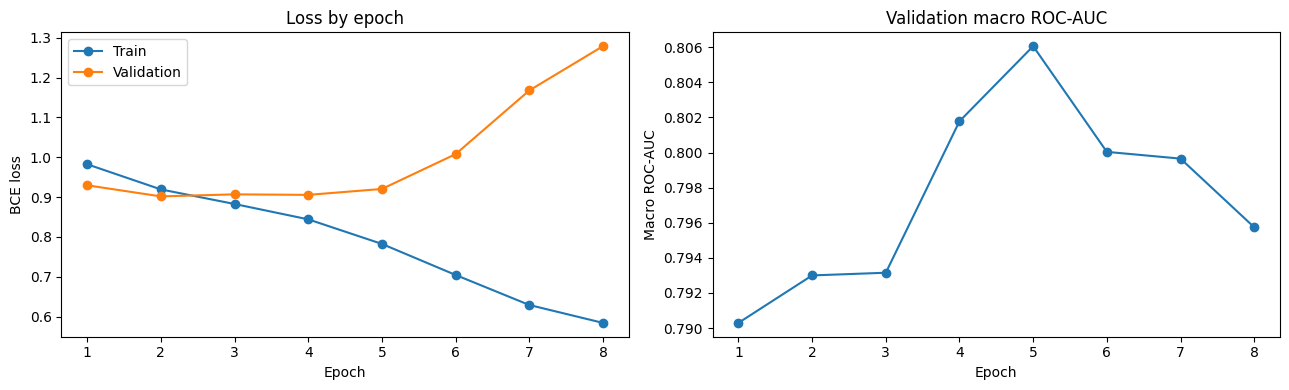

In [9]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_ran, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs_ran, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()
axes[1].plot(epochs_ran, history["val_macro_roc_auc"], marker="o")
axes[1].set_title("Validation macro ROC-AUC"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro ROC-AUC")
plt.tight_layout()
plt.show()

## 9. Load best checkpoint and evaluate the held-out test set

The test set is evaluated only after model selection. AUC/AP are marked `NaN` if undefined for a class; they are never replaced with a fabricated score. Metrics at threshold 0.5 are reported for reference only.

In [10]:
state = torch.load(best_weights_path, map_location=device)
model.load_state_dict(state)
model.eval()

test_loss, test_macro_auc, test_aucs, y_test, p_test = run_eval(model, test_loader, criterion)

metric_rows = []
for i, label in enumerate(TARGET_CONDITIONS):
    y = y_test[:, i].astype(int)
    p = p_test[:, i]
    auc = test_aucs[i]
    ap = float(average_precision_score(y, p)) if len(np.unique(y)) > 1 else float("nan")
    pred05 = (p >= 0.5).astype(int)
    metric_rows.append({
        "condition": label,
        "positive_count": int(y.sum()),
        "prevalence_pct": round(float(y.mean() * 100), 3),
        "ROC_AUC": auc,
        "Average_Precision": ap,
        "precision_at_0.5": float(precision_score(y, pred05, zero_division=0)),
        "sensitivity_at_0.5": float(recall_score(y, pred05, zero_division=0)),
        "specificity_at_0.5": float(recall_score(1-y, 1-pred05, zero_division=0)),
        "F1_at_0.5": float(f1_score(y, pred05, zero_division=0)),
    })

metrics_df = pd.DataFrame(metric_rows)
print(f"Test loss: {test_loss:.4f}")
print(f"Test macro ROC-AUC (defined classes only): {test_macro_auc:.4f}")
display(metrics_df)

Test loss: 0.9492
Test macro ROC-AUC (defined classes only): 0.8070


,condition,positive_count,prevalence_pct,ROC_AUC,Average_Precision,precision_at_0.5,sensitivity_at_0.5,specificity_at_0.5,F1_at_0.5
0,Cardiomegaly,456,2.738,0.917651,0.351073,0.166121,0.778509,0.889986,0.273814
1,Pneumonia,210,1.261,0.736491,0.041863,0.034151,0.557143,0.798772,0.064356
2,Effusion,1897,11.391,0.871895,0.473601,0.332748,0.798629,0.794132,0.469767
3,Infiltration,2961,17.780,0.710266,0.352267,0.319022,0.577170,0.733587,0.410916
4,Atelectasis,1701,10.214,0.798662,0.310263,0.237162,0.711346,0.739718,0.355725


## 10. Choose per-label thresholds on Validation only

Thresholds are selected by maximizing validation F1 for each label. This is a development heuristic, not a clinical operating point. In a real deployment, thresholds should be selected against the intended use and sensitivity/specificity requirements, then locked before final external validation.

In [11]:
_, _, _, y_val, p_val = run_eval(model, val_loader, criterion)

def choose_f1_threshold(y, p):
    if len(np.unique(y)) < 2:
        return 0.5
    precision, recall, thresholds = precision_recall_curve(y, p)
    if len(thresholds) == 0:
        return 0.5
    # precision/recall arrays have one more element than thresholds.
    f1 = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)
    best_idx = int(np.nanargmax(f1))
    return float(np.clip(thresholds[best_idx], 0.01, 0.99))

thresholds = {
    label: choose_f1_threshold(y_val[:, i].astype(int), p_val[:, i])
    for i, label in enumerate(TARGET_CONDITIONS)
}
print("Validation-derived thresholds (not clinically validated):")
display(pd.DataFrame({"condition": TARGET_CONDITIONS,
                      "threshold": [thresholds[c] for c in TARGET_CONDITIONS]}))

# Report held-out test metrics using thresholds chosen only on validation.
threshold_metric_rows = []
for i, label in enumerate(TARGET_CONDITIONS):
    y = y_test[:, i].astype(int)
    pred = (p_test[:, i] >= thresholds[label]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    threshold_metric_rows.append({
        "condition": label,
        "threshold": thresholds[label],
        "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "precision": tp / (tp + fp) if (tp + fp) else np.nan,
        "F1": f1_score(y, pred, zero_division=0),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
    })
threshold_metrics_df = pd.DataFrame(threshold_metric_rows)
display(threshold_metrics_df)

Validation-derived thresholds (not clinically validated):


,condition,threshold
0,Cardiomegaly,0.939453
1,Pneumonia,0.766602
2,Effusion,0.789551
3,Infiltration,0.549316
4,Atelectasis,0.649902


,condition,threshold,sensitivity,specificity,precision,F1,TP,FP,TN,FN
0,Cardiomegaly,0.939453,0.392544,0.984010,0.408676,0.400447,179,259,15939,277
1,Pneumonia,0.766602,0.209524,0.961749,0.065379,0.099660,44,629,15815,166
2,Effusion,0.789551,0.561413,0.917056,0.465269,0.508839,1065,1224,13533,832
3,Infiltration,0.549316,0.517393,0.787921,0.345356,0.414222,1532,2904,10789,1429
4,Atelectasis,0.649902,0.537919,0.847656,0.286564,0.373927,915,2278,12675,786


## 11. ROC and Precision–Recall curves

Precision–Recall curves are particularly important for rare findings. These plots describe performance on this dataset and do not establish generalization to other hospitals or populations.

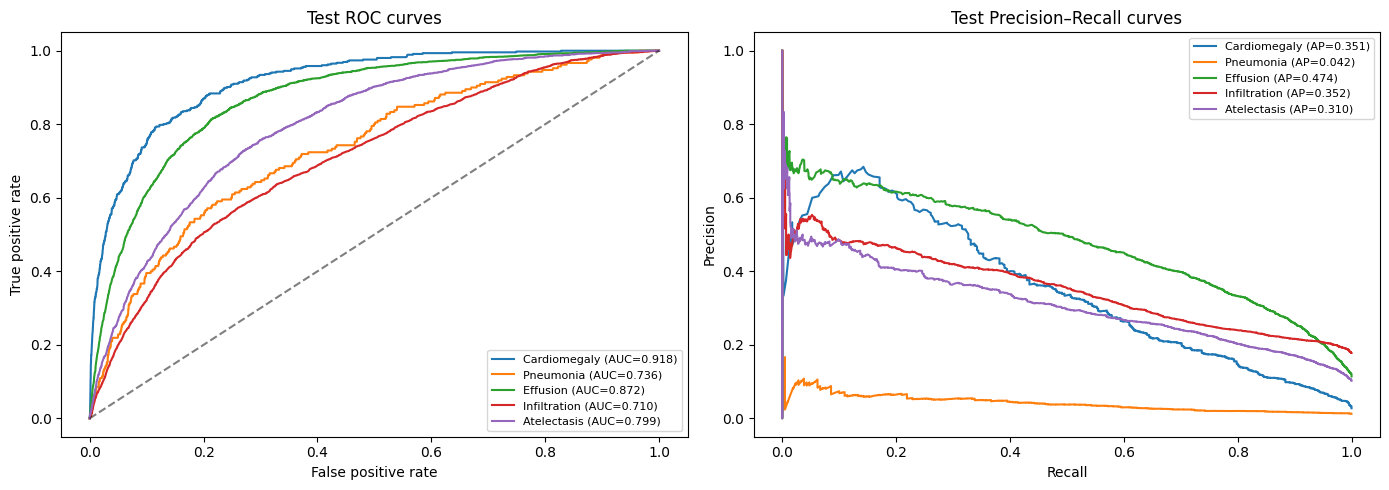

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, label in enumerate(TARGET_CONDITIONS):
    y = y_test[:, i].astype(int)
    p = p_test[:, i]
    if len(np.unique(y)) < 2:
        continue
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={test_aucs[i]:.3f})")
    precision, recall, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)
    axes[1].plot(recall, precision, label=f"{label} (AP={ap:.3f})")
axes[0].plot([0,1], [0,1], "k--", alpha=0.5)
axes[0].set_title("Test ROC curves"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[1].set_title("Test Precision–Recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 12. Grad-CAM explainability sanity check

Grad-CAM is an exploratory visualization, not proof that the model used a clinically valid feature. The target is the final convolutional feature map (`model.features.denseblock4`), which has spatial dimensions and avoids attaching a backward hook to an individual DenseNet layer.

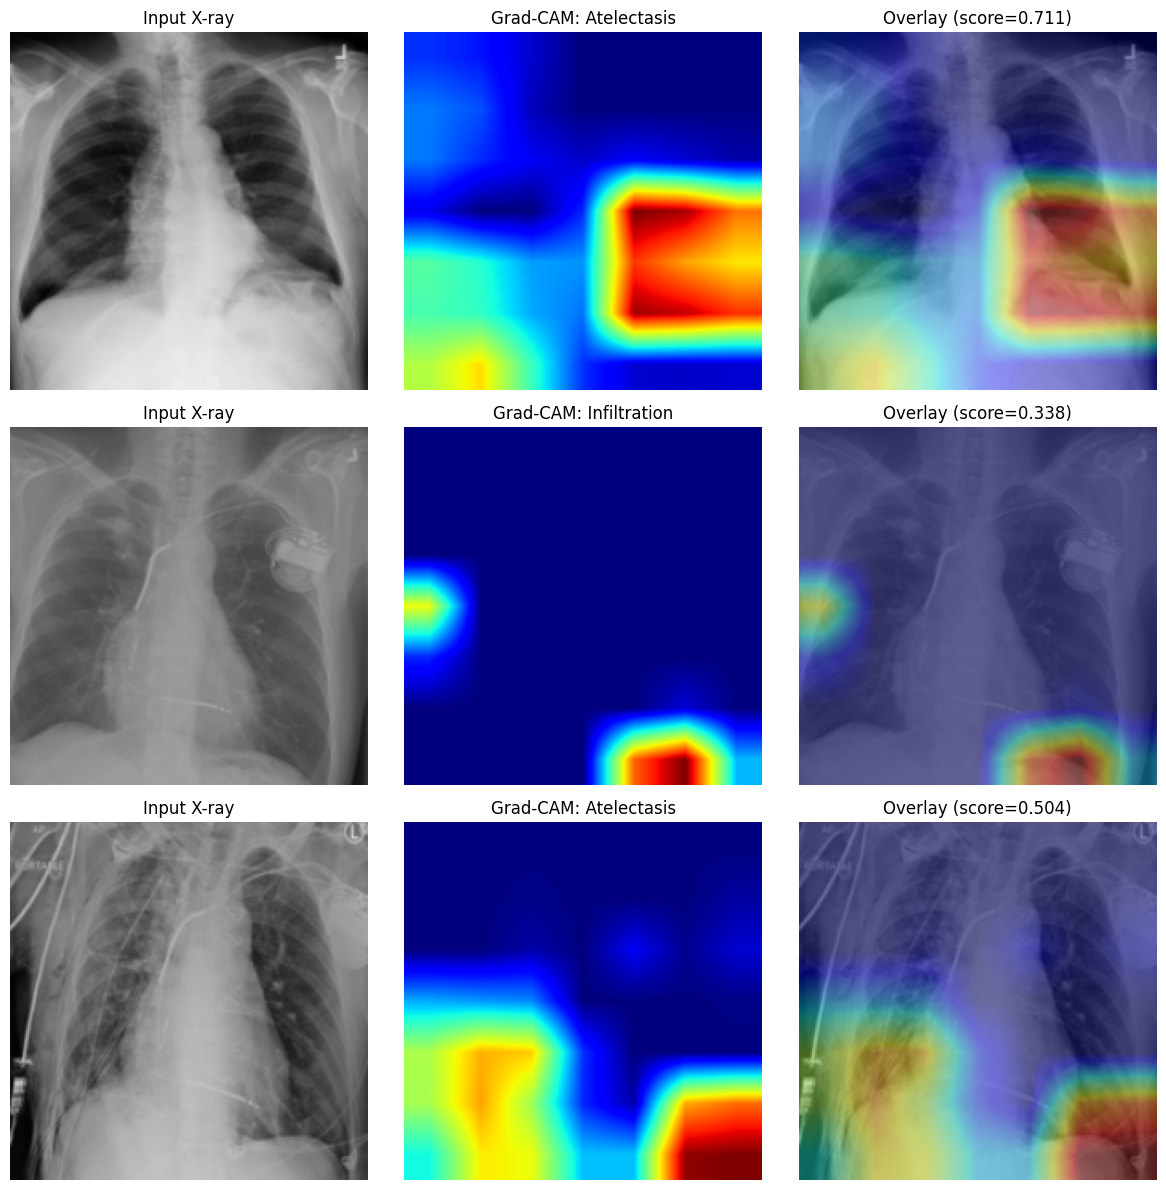

In [13]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.fwd_handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.activations = output
        # Tensor hook avoids module backward-hook issues with in-place ReLUs.
        if output.requires_grad:
            output.register_hook(self._tensor_gradient_hook)

    def _tensor_gradient_hook(self, gradient):
        self.gradients = gradient

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        score = logits[:, class_idx].sum()
        score.backward()
        if self.activations is None or self.gradients is None:
            raise RuntimeError("Grad-CAM hooks did not capture activations/gradients.")
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(
            cam, size=input_tensor.shape[-2:], mode="bilinear", align_corners=False
        )
        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam, torch.sigmoid(logits)[0].detach().cpu().numpy()

    def close(self):
        self.fwd_handle.remove()

# Use the last dense block output as the target feature map.
explainer = GradCAM(model, model.features.denseblock4)
model.eval()
sample_images, sample_labels = next(iter(test_loader))
n_show = min(3, len(sample_images))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4*n_show), squeeze=False)
for i in range(n_show):
    x = sample_images[i:i+1].to(device)
    with torch.no_grad():
        initial_probs = torch.sigmoid(model(x))[0].detach().cpu().numpy()
    class_idx = int(np.argmax(initial_probs))
    cam, probs = explainer.generate(x, class_idx)
    img = sample_images[i].permute(1,2,0).numpy()
    img = np.clip(img * np.array(NORMALIZE_STD) + np.array(NORMALIZE_MEAN), 0, 1)
    axes[i,0].imshow(img); axes[i,0].set_title("Input X-ray"); axes[i,0].axis("off")
    axes[i,1].imshow(cam, cmap="jet"); axes[i,1].set_title(f"Grad-CAM: {TARGET_CONDITIONS[class_idx]}"); axes[i,1].axis("off")
    axes[i,2].imshow(img); axes[i,2].imshow(cam, cmap="jet", alpha=0.4)
    axes[i,2].set_title(f"Overlay (score={probs[class_idx]:.3f})"); axes[i,2].axis("off")
plt.tight_layout()
plt.show()
explainer.close()

## 13. Export backend-compatible weights, metadata, and metrics

The `.pth` file is saved with the exact legacy filename. The model architecture and classifier head remain compatible with the previous notebook's state-dict layout. The JSON metadata is strongly recommended for the backend because it defines class order, image size, normalization, and validation-derived thresholds.

In [14]:
# Ensure the best validation checkpoint is the model exported.
model.load_state_dict(torch.load(best_weights_path, map_location=device))
model = model.to(device).eval()

weights_path = OUTPUT_DIR / WEIGHTS_FILENAME
metadata_path = OUTPUT_DIR / METADATA_FILENAME
metrics_path = OUTPUT_DIR / METRICS_FILENAME

# Save only state_dict to preserve compatibility with the existing backend loader.
torch.save(model.state_dict(), weights_path)

metadata = {
    "model_name": "MediVision AI Chest X-ray DenseNet-121",
    "architecture": "torchvision.models.densenet121",
    "classifier_head": "Linear(1024,512)->ReLU->Dropout(0.2)->Linear(512,5)",
    "weights_filename": WEIGHTS_FILENAME,
    "num_classes": len(TARGET_CONDITIONS),
    "class_names": TARGET_CONDITIONS,
    "image_size": IMAGE_SIZE,
    "resize_short_side": 256,
    "crop": "CenterCrop(224)",
    "normalization": {"mean": NORMALIZE_MEAN, "std": NORMALIZE_STD},
    "thresholds_validation_f1": thresholds,
    "thresholds_warning": "Development thresholds only; not clinically validated.",
    "pretrained_imagenet": USE_PRETRAINED,
    "seed": SEED,
    "best_validation_macro_roc_auc": float(best_val_auc),
    "test_macro_roc_auc": float(test_macro_auc) if np.isfinite(test_macro_auc) else None,
    "target_conditions": TARGET_CONDITIONS,
    "label_source": "NIH ChestX-ray14 report-derived labels; known label noise applies.",
    "clinical_status": "Research/development only; not clinically validated."
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

def records_with_json_nulls(frame):
    # Convert pandas/numpy NaN and infinity to JSON nulls.
    clean = frame.astype(object).where(pd.notna(frame), None)
    records = clean.to_dict(orient="records")
    for row in records:
        for key, value in list(row.items()):
            if isinstance(value, (np.floating, float)) and not np.isfinite(value):
                row[key] = None
            elif isinstance(value, np.integer):
                row[key] = int(value)
    return records

metrics_payload = {
    "test_loss": float(test_loss),
    "test_macro_roc_auc": float(test_macro_auc) if np.isfinite(test_macro_auc) else None,
    "per_class_test_metrics_threshold_0_5": records_with_json_nulls(metrics_df),
    "per_class_test_metrics_validation_thresholds": records_with_json_nulls(threshold_metrics_df),
    "training_history": history,
    "split_summary": records_with_json_nulls(split_summary),
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2, allow_nan=False)

print("Exported artifacts:")
for p in [weights_path, metadata_path, metrics_path]:
    print(f" - {p} ({p.stat().st_size / (1024**2):.2f} MiB)")

Exported artifacts:
 - /kaggle/working/chest_xray_densenet121.pth (29.13 MiB)
 - /kaggle/working/chest_xray_densenet121_metadata.json (0.00 MiB)
 - /kaggle/working/chest_xray_densenet121_metrics.json (0.00 MiB)


## 14. Reload verification and final handoff

This verifies state-dict compatibility, output shape, and finite probabilities using a real preprocessed test image. It is a technical smoke test, not a performance or clinical validation.

In [15]:
# Fresh model, no pretrained download needed, then strict state-dict load.
verification_model = build_densenet121_classifier(num_classes=len(TARGET_CONDITIONS), pretrained=False)
loaded_state = torch.load(weights_path, map_location="cpu")
verification_model.load_state_dict(loaded_state, strict=True)
verification_model.eval()

real_batch, _ = next(iter(test_loader))
with torch.no_grad():
    logits = verification_model(real_batch[:1].cpu())
    probs = torch.sigmoid(logits)
assert tuple(logits.shape) == (1, len(TARGET_CONDITIONS))
assert torch.isfinite(probs).all(), "Non-finite output detected."
assert ((probs >= 0) & (probs <= 1)).all()

print("Reload verification passed.")
print("Output logits shape:", tuple(logits.shape))
print("Sample probabilities:")
display(pd.DataFrame({"condition": TARGET_CONDITIONS, "probability": probs[0].numpy()}))

print("\nDOWNLOAD THESE FILES FROM KAGGLE /kaggle/working:")
print(f"1. {WEIGHTS_FILENAME}  <-- required model weights; keep exact filename")
print(f"2. {METADATA_FILENAME}  <-- recommended for class order/preprocessing/thresholds")
print(f"3. {METRICS_FILENAME}   <-- experiment audit report")
print("\nCopy the .pth file to the exact models path expected by your existing MediVision backend.")
print("Do not assume the path is correct until you verify the backend's model-loading code.")
print("If backend preprocessing differs from metadata, update backend preprocessing or retrain; do not mix them.")

Reload verification passed.
Output logits shape: (1, 5)
Sample probabilities:


,condition,probability
0,Cardiomegaly,0.008919
1,Pneumonia,0.511972
2,Effusion,0.626510
3,Infiltration,0.486286
4,Atelectasis,0.711167



DOWNLOAD THESE FILES FROM KAGGLE /kaggle/working:
1. chest_xray_densenet121.pth  <-- required model weights; keep exact filename
2. chest_xray_densenet121_metadata.json  <-- recommended for class order/preprocessing/thresholds
3. chest_xray_densenet121_metrics.json   <-- experiment audit report

Copy the .pth file to the exact models path expected by your existing MediVision backend.
Do not assume the path is correct until you verify the backend's model-loading code.
If backend preprocessing differs from metadata, update backend preprocessing or retrain; do not mix them.
